# 5. A KDE detector for Kelmarsh

The same detector as notebook 4, on the wind turbines. Same recipe, so the two
results can be compared directly: scale on a period of normal operation, fit a KDE,
and score every row by its negative log density. High score means unlikely.

The one deliberate difference is the choice of sensors. Notebook 2 found that the
bearing temperatures mostly tell us how hard the wind was blowing. So we give the
model power and wind speed as well. It then learns which temperature is normal *for
a given load*, and a high score means a temperature that does not fit the power,
not just a high temperature.

The output is one score column per turbine, saved to `results/`.

In [1]:
import os
import zipfile

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KernelDensity

DATA = '../data/Kelmarsh_SCADA_2017_3083.zip'
TURBINES = [1, 2, 3, 4, 5, 6]

SENSORS = ['Front bearing temperature (°C)',
           'Rear bearing temperature (°C)',
           'Generator bearing rear temperature (°C)',
           'Power (kW)',
           'Wind speed (m/s)']

## The data

Same loading as notebook 2. Like notebook 4 we drop rows with any missing sensor,
which removes the 1.2 % of slots where the turbine logged nothing.

In [2]:
def read_file(kind, turbine):
    '''Read one CSV from the zip. kind is 'Turbine_Data' or 'Status'.'''
    with zipfile.ZipFile(DATA) as z:
        prefix = f'{kind}_Kelmarsh_{turbine}_'
        name = [n for n in z.namelist() if n.startswith(prefix)][0]
        with z.open(name) as f:
            return pd.read_csv(f, skiprows=9, na_values='-')


def load_turbine(turbine):
    '''The five sensors for one turbine, rows with gaps removed.'''
    d = read_file('Turbine_Data', turbine)
    d.index = pd.to_datetime(d['# Date and time'])
    d.index.name = 'timestamp'
    return d[SENSORS].dropna()

The failure label is also built as in notebook 2: forced outage lines from the
status log, with overlapping lines merged into one event.

In [3]:
def merge_overlapping(log):
    '''Join log lines that overlap in time into one event per fault.'''
    events = []
    for row in log.sort_values('start').itertuples():
        if events and row.start <= events[-1]['end']:
            events[-1]['end'] = max(events[-1]['end'], row.end)
        else:
            events.append({'start': row.start, 'end': row.end, 'message': row.Message})
    return pd.DataFrame(events)


def forced_outages(turbine):
    '''Forced outage events for one turbine, with their length in hours.'''
    log = read_file('Status', turbine)
    log['start'] = pd.to_datetime(log['Timestamp start'])
    log['end'] = pd.to_datetime(log['Timestamp end'])
    events = merge_overlapping(log[log['IEC category'] == 'Forced outage'])
    events['hours'] = (events['end'] - events['start']).dt.total_seconds() / 3600
    return events


outages = {t: forced_outages(t) for t in TURBINES}

data = load_turbine(1)
print(f'turbine 1: {len(data):,} ten-minute rows from {data.index.min()} to {data.index.max()}')

turbine 1: 51,932 ten-minute rows from 2017-01-01 00:00:00 to 2017-12-31 23:50:00


## Which period counts as normal?

The model only ever sees this stretch, so the choice matters more than anything else
in the notebook. It must not contain a forced outage, and we want the same period for
all six turbines so that there is one rule to explain, not six.

Where are the outages?

In [4]:
per_month = pd.DataFrame({t: outages[t]['start'].dt.month.value_counts() for t in TURBINES})
per_month = per_month.reindex(range(1, 13)).fillna(0).astype(int)
per_month.index.name = 'month'
per_month.columns = [f'turbine {t}' for t in TURBINES]
per_month.T

month,1,2,3,4,5,6,7,8,9,10,11,12
turbine 1,21,7,0,0,0,0,0,2,0,1,0,0
turbine 2,6,10,0,0,0,2,0,0,0,1,0,0
turbine 3,0,6,0,0,0,1,1,0,0,1,1,0
turbine 4,8,14,0,0,0,0,0,0,0,1,0,0
turbine 5,1,11,2,0,0,1,0,0,1,1,0,0
turbine 6,11,13,4,2,0,0,0,1,1,6,2,1


Most outages are in January and February. The longest stretch that is free of forced
outages on **every** turbine runs from 22 April (the day after turbine 6's last spring
outage) to 5 June (the day before turbine 2's next one).

We stop two days earlier, on **3 June**. Below we look for warnings in the two days
before each outage, and turbine 2's outage on 6 June would otherwise have its warning
window inside the training data. The model would then have been taught that those
exact rows are normal. That leaves six weeks.

Before committing we check the standard deviation of each sensor in that period, as
notebook 4 did. A sensor that barely moves would make `StandardScaler` divide by
nearly zero and drown out the others. We compare it against May alone and against
the whole year.

In [5]:
candidates = {
    'May only':       data.loc['2017-05-01':'2017-05-31'],
    '22 Apr - 3 Jun': data.loc['2017-04-22':'2017-06-03'],
    'whole year':     data,
}

print('standard deviation of each sensor within the candidate periods\n')
print(pd.DataFrame({name: part.std() for name, part in candidates.items()}).round(2))

standard deviation of each sensor within the candidate periods

                                         May only  22 Apr - 3 Jun  whole year
Front bearing temperature (°C)               9.76            9.72        9.33
Rear bearing temperature (°C)                7.96            7.93        7.70
Generator bearing rear temperature (°C)      2.83            2.92        4.06
Power (kW)                                 489.39          475.66      599.80
Wind speed (m/s)                             2.30            2.25        2.66


No sensor is close to constant. The training period spreads about as much as the
whole year for every sensor except the generator bearing, which varies less (2.9 °C
against 4.1 °C). That makes sense: notebook 2 showed it follows the season, and six
weeks of spring do not contain a season. So the scaling problem from notebook 4
does not appear here, and we train on **22 April to 3 June**.

The cost of this choice is worth writing down now, because it will show up below:
the model has never seen winter, and it has never seen a storm. The strongest wind
in the training period is about 13 m/s.

In [6]:
TRAIN = ('2017-04-22', '2017-06-03')

train = data.loc[TRAIN[0]:TRAIN[1]]

scaler = StandardScaler().fit(train)
X_train = scaler.transform(train)
X_all = scaler.transform(data)

print(f'training on {len(train):,} rows, scoring all {len(data):,}')

training on 6,190 rows, scoring all 51,932


## Fitting the density

Exactly as in notebook 4: a Gaussian bump on each of 5000 randomly chosen training
rows, and the score is the negative log density.

In [7]:
rng = np.random.default_rng(0)
sample = rng.choice(len(X_train), size=5000, replace=False)


def kde_scores(bandwidth):
    '''Fit a KDE on the training sample and score every row. High = unusual.'''
    kde = KernelDensity(bandwidth=bandwidth).fit(X_train[sample])
    return pd.Series(-kde.score_samples(X_all), index=data.index)

## What counts as "before" and "during" an outage

On MetroPT we compared the score inside the failure periods against everything else.
Here that comparison would be misleading. While a turbine stands still with wind
blowing, power is zero at a wind speed that normally gives hundreds of kW, so of
course the score is high. That is the model noticing the stop, which the status log
already tells us. It is not a warning.

So we look at two windows separately:

- **during**: from start to end of each forced outage.
- **before**: the two days leading up to it, the same lead time as `lead=` in
  `util/evaluation.py`. Rows that are inside another outage are not counted as before.

Everything else is **normal**. The question for maintenance is whether "before"
scores higher than "normal".

In [8]:
def outage_windows(index, events):
    '''Two True/False series: rows in the 2 days before an outage, and rows during one.'''
    before = pd.Series(False, index=index)
    during = pd.Series(False, index=index)
    for row in events.itertuples():
        before.loc[row.start - pd.Timedelta(days=2):row.start] = True
        during.loc[row.start:row.end] = True
    return before & ~during, during


before, during = outage_windows(data.index, outages[1])
normal = ~(before | during)

print(f'normal: {normal.sum():,} rows, before: {before.sum():,}, during: {during.sum():,}')

normal: 49,073 rows, before: 2,536, during: 323


## Choosing the bandwidth

Same three values as notebook 4.

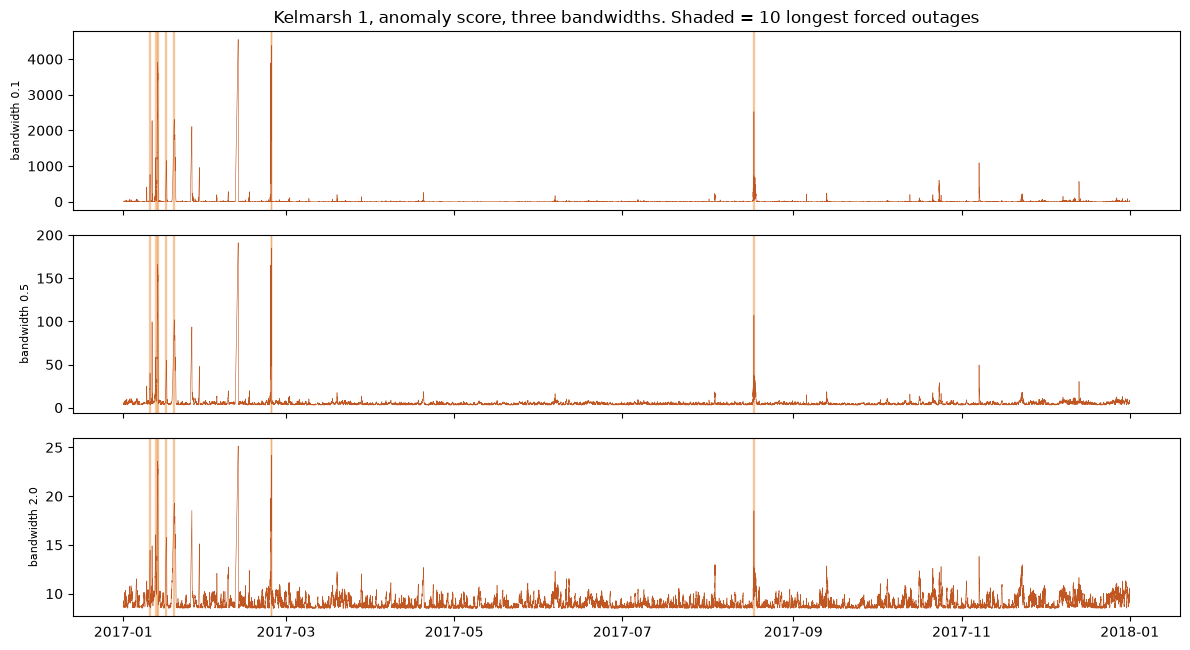

In [9]:
def mark_outages(ax, events, n=10):
    '''Shade the n longest outages on a plot.'''
    for row in events.nlargest(n, 'hours').itertuples():
        ax.axvspan(row.start, row.end, color='sandybrown', alpha=0.5, lw=1)


bandwidths = [0.1, 0.5, 2.0]
tried = {b: kde_scores(b) for b in bandwidths}

fig, axes = plt.subplots(len(bandwidths), 1, figsize=(12, 2.2 * len(bandwidths)),
                         sharex=True)

for ax, b in zip(axes, bandwidths):
    ax.plot(tried[b].index, tried[b], lw=0.4, color='#c05621')
    ax.set_ylabel(f'bandwidth {b}', fontsize=8)
    mark_outages(ax, outages[1])

axes[0].set_title('Kelmarsh 1, anomaly score, three bandwidths. Shaded = 10 longest forced outages')
plt.tight_layout()

As in notebook 4 we summarise with the 99th percentile of normal operation as the
reference line. By definition 1 % of normal rows lie above it. If the rows before an
outage are no different, about 1 % of them will be above it too.

In [10]:
summary = pd.DataFrame({
    'median normal':   {b: s[normal].median() for b, s in tried.items()},
    '99th pct normal': {b: s[normal].quantile(0.99) for b, s in tried.items()},
    'median before':   {b: s[before].median() for b, s in tried.items()},
    'median during':   {b: s[during].median() for b, s in tried.items()},
})
for b, s in tried.items():
    line = summary.loc[b, '99th pct normal']
    summary.loc[b, 'before above line'] = (s[before] > line).mean()
    summary.loc[b, 'during above line'] = (s[during] > line).mean()

summary.round(2)

,median normal,99th pct normal,median before,median during,before above line,during above line
0.1,1.12,75.18,2.20,734.45,0.10,0.85
0.5,4.35,11.50,5.04,38.51,0.10,0.85
2.0,8.76,11.33,8.97,14.39,0.07,0.74


## Choosing one

As on MetroPT, the bandwidth hardly matters. Between 7 and 10 % of the rows before an
outage are above the line under all three values, and the during-share drops only at
2.0, where everything is squeezed flat. We take **0.5**, the same as notebook 4, so that the
two datasets are scored the same way. It was not tuned, and we should say so.

Two things in the table matter more than the bandwidth:

- **During** an outage the score is far above normal. As explained above, that is the
  stop itself.
- **Before** an outage, about 10 % of rows are above the line instead of the 1 % we
  would expect by chance. That looks like a warning. The rest of the notebook checks
  whether it is one.

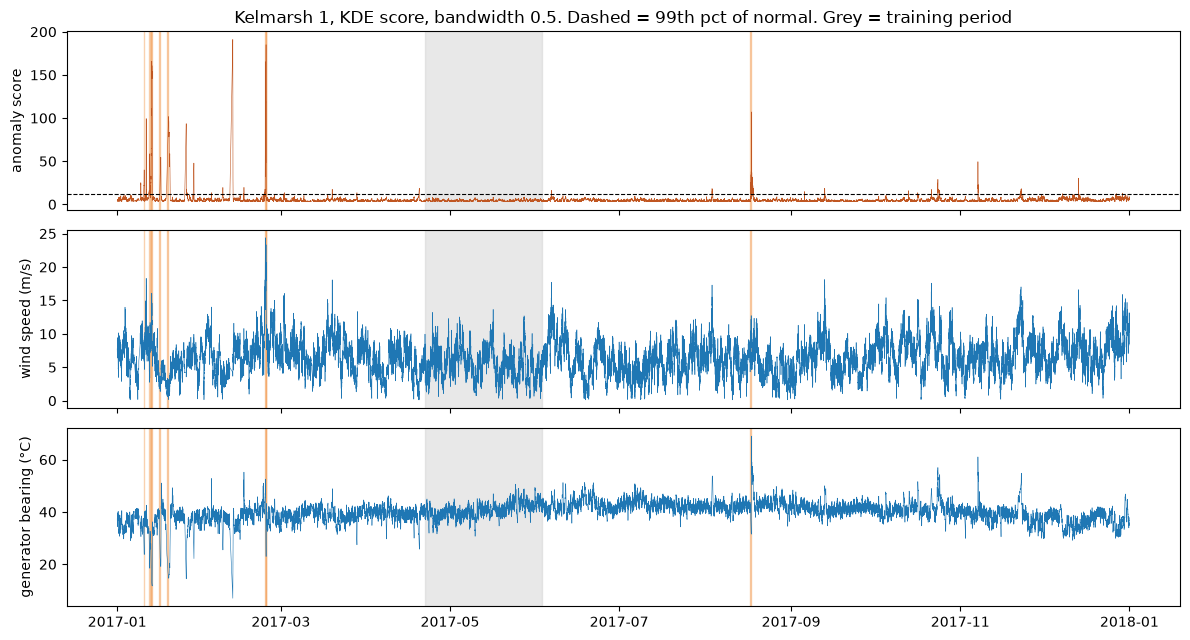

In [11]:
BANDWIDTH = 0.5
scores = tried[BANDWIDTH]
line = summary.loc[BANDWIDTH, '99th pct normal']

fig, axes = plt.subplots(3, 1, figsize=(12, 6.5), sharex=True)

axes[0].plot(scores.index, scores, lw=0.4, color='#c05621')
axes[0].axhline(line, color='black', lw=0.8, ls='--')
axes[0].set_ylabel('anomaly score')

axes[1].plot(data.index, data['Wind speed (m/s)'], lw=0.4)
axes[1].set_ylabel('wind speed (m/s)')

axes[2].plot(data.index, data['Generator bearing rear temperature (°C)'], lw=0.4)
axes[2].set_ylabel('generator bearing (°C)')

for ax in axes:
    mark_outages(ax, outages[1])
    ax.axvspan(pd.Timestamp(TRAIN[0]), pd.Timestamp(TRAIN[1]), color='lightgrey', alpha=0.5)

axes[0].set_title(f'Kelmarsh 1, KDE score, bandwidth {BANDWIDTH}. '
                  'Dashed = 99th pct of normal. Grey = training period')
plt.tight_layout()

The score is quiet for most of the year, with clusters of spikes in January and
February and one in mid-August. Two things stand out:

- The tallest spike, on 11 February, is **not a forced outage**. The log shows a 26-hour
  grid loss, which IEC files as "Out of Electrical Specification". When the turbine
  restarts with cold bearings, the score jumps to almost 200. The detector reacts to
  every stop, whatever the log calls it.
- The August spike sits at a generator fan overload, and the generator bearing
  temperature jumps with it. We come back to that below.

## Why are the high scores high?

Every value in `X_all` is a sensor reading in standard deviations from the training
period. For each row above the line we can therefore ask which sensor is furthest from
what the model has seen, and in which direction.

In [12]:
scaled = pd.DataFrame(X_all, index=data.index, columns=SENSORS)
high = scaled[scores > line]

furthest = high.abs().idxmax(axis=1)
direction = np.where(high.abs().max(axis=1) == high.max(axis=1), 'high', 'low')
reason = furthest.str.replace(r' \(.*\)', '', regex=True) + ' ' + direction

print(f'{len(high):,} rows above the line. The sensor furthest from training:\n')
print(reason.value_counts())

1,021 rows above the line. The sensor furthest from training:

Generator bearing rear temperature low     535
Generator bearing rear temperature high    251
Wind speed high                            147
Rear bearing temperature low                88
Name: count, dtype: int64


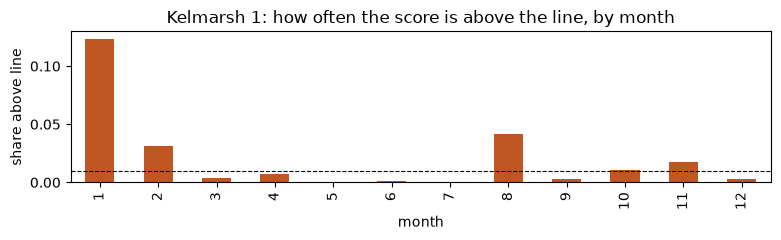

In [13]:
high_by_month = (scores > line).groupby(scores.index.month).mean()

ax = high_by_month.plot.bar(figsize=(8, 2.5), color='#c05621')
ax.axhline(0.01, color='black', lw=0.8, ls='--')
ax.set_xlabel('month')
ax.set_ylabel('share above line')
ax.set_title('Kelmarsh 1: how often the score is above the line, by month')
plt.tight_layout()

Three quarters of the high scores come from the **generator bearing being outside
its spring range**. Colder is winter, or a turbine that has stood still for hours.
Warmer is a handful of short episodes; the largest by far is 17–18 August, the case
we look at next. The remaining
high scores are mostly wind stronger than anything in the training period: storms.

## The one case that fits the design

The model was built to flag a temperature that does not fit the load. The clearest
case on turbine 1 is around the generator fan overload on 17 August.

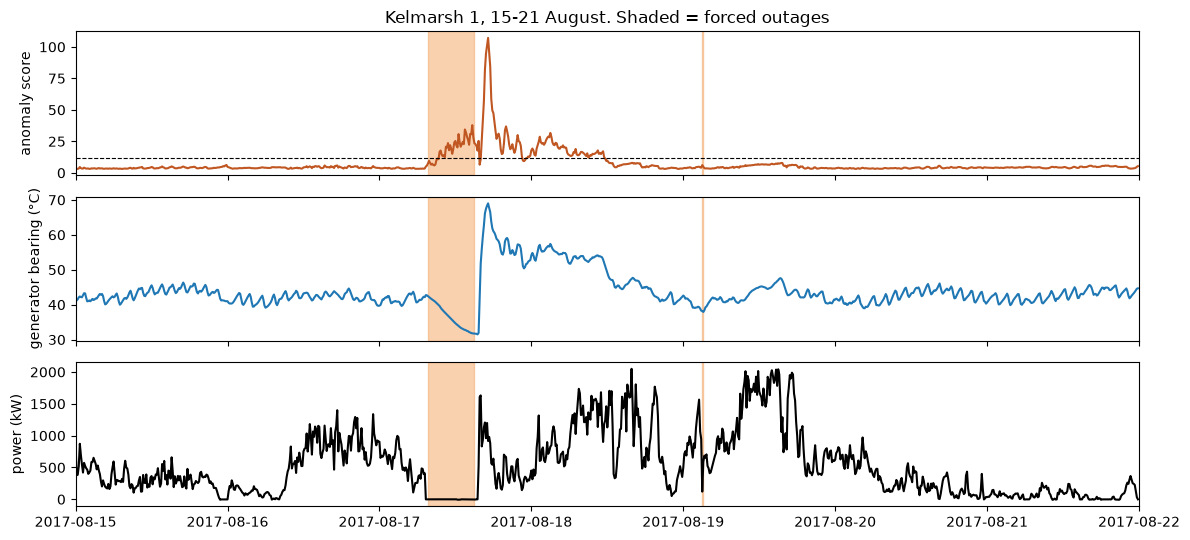

In [14]:
week = slice('2017-08-15', '2017-08-21')

fig, axes = plt.subplots(3, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(scores.loc[week].index, scores.loc[week], color='#c05621')
axes[0].axhline(line, color='black', lw=0.8, ls='--')
axes[0].set_ylabel('anomaly score')
axes[1].plot(data.loc[week].index, data.loc[week, 'Generator bearing rear temperature (°C)'])
axes[1].set_ylabel('generator bearing (°C)')
axes[2].plot(data.loc[week].index, data.loc[week, 'Power (kW)'], color='black')
axes[2].set_ylabel('power (kW)')

for ax in axes:
    mark_outages(ax, outages[1], n=len(outages[1]))

axes[0].set_xlim(pd.Timestamp('2017-08-15'), pd.Timestamp('2017-08-22'))
axes[0].set_title('Kelmarsh 1, 15-21 August. Shaded = forced outages')
plt.tight_layout()

After the fan overload the turbine restarts and runs at normal power, but the
generator bearing sits around 55 °C for about a day, against roughly 40 °C at the
same load in spring. That is a temperature that does not fit the load, and the score
is above the line the whole time. The fans were probably not cooling properly.

But it comes **after** the outage, not before it. It is the consequence of the fault,
not a warning of it. (The rows still land in a "before" window, because an unrelated
yaw fault follows on 19 August.)

The same thing, smaller, happens on 23 October: after a remote stop on all six
turbines the generator bearing climbs from 41 to 54 °C at low power, and the score
rises with it. Again after the stop, not before.

The August case also suggests this fan overload was a real fault. Notebook 2 suspected the fan
overloads in January–March were a technician's service round; this one is different.

## A fair comparison

Back to the 10 % before outages. Most outages are in January, and
January is when the score is high anyway. So the fair comparison is not "before vs
all normal rows", but "before vs normal rows **in the same month**".

For each row in a before-window we look up how often normal rows in that calendar
month are above the line, and average. That is how many high rows we would expect
before an outage if outages had nothing to do with the score.

In [15]:
def compare_before(scores, before, during, line):
    '''Share of rows above the line before outages, and what the month alone would predict.'''
    normal = ~(before | during)
    above = scores > line

    normal_above = above[normal]
    rate_by_month = normal_above.groupby(normal_above.index.month).mean()
    expected = rate_by_month.reindex(scores.index[before].month).mean()

    return {
        'before above line': above[before].mean(),
        'expected from month': expected,
        'during above line': above[during].mean(),
    }


pd.Series(compare_before(scores, before, during, line)).round(3)

before above line      0.101
expected from month    0.049
during above line      0.845
dtype: float64

On turbine 1 the month explains about half of the high rows before outages. Most of
the other half is the hot generator bearing on 17–18 August from the section above.
Now across all six turbines.

## All six turbines

The same chain in a loop: the same training period, the same 5000-row sample size,
bandwidth 0.5, and a model per turbine.

For the high-scoring rows in the before-windows we also record two things that are
not a fault developing: whether the turbine was **already stopped** (power under
10 kW, usually after an earlier stop), and whether the wind was **stronger than
anything in the training period**.

In [16]:
all_scores = {}
rows = []

for turbine in TURBINES:
    d = load_turbine(turbine)
    tr = d.loc[TRAIN[0]:TRAIN[1]]

    sc = StandardScaler().fit(tr)
    X_tr = sc.transform(tr)
    pick = np.random.default_rng(0).choice(len(X_tr), size=5000, replace=False)
    kde = KernelDensity(bandwidth=BANDWIDTH).fit(X_tr[pick])
    s = pd.Series(-kde.score_samples(sc.transform(d)), index=d.index)
    all_scores[turbine] = s

    bef, dur = outage_windows(d.index, outages[turbine])
    ln = s[~(bef | dur)].quantile(0.99)
    result = compare_before(s, bef, dur, ln)

    high_before = d[bef & (s > ln)]
    result['high before: already stopped'] = (high_before['Power (kW)'] < 10).mean()
    result['high before: wind beyond training'] = (
        high_before['Wind speed (m/s)'] > tr['Wind speed (m/s)'].max()).mean()
    result['turbine'] = turbine
    rows.append(result)

results = pd.DataFrame(rows).set_index('turbine')
results.round(3)

,before above line,expected from month,during above line,high before: already stopped,high before: wind beyond training
turbine,,,,,
1,0.101,0.049,0.845,0.358,0.117
2,0.122,0.024,0.722,0.682,0.164
3,0.042,0.015,0.500,0.425,0.466
4,0.017,0.029,0.477,0.393,0.571
5,0.026,0.019,0.424,0.660,0.404
6,0.025,0.017,0.875,0.486,0.420


Reading the table row by row:

- **During** outages the score is above the line 40–90 % of the time on every
  turbine. The model sees the turbines stop.
- **Before** outages, turbines 4, 5 and 6 are at or near what the month alone predicts:
  no warning.
- Turbines 1, 2 and 3 are higher than the month predicts, and each has an explanation
  that is not a developing fault:
  - Turbine 2: two thirds of its high rows before outages are a turbine that is
    **already stopped**. Outages come in clusters, so the two days before one often
    contain the previous one.
  - Turbine 3: higher than the month predicts, and close to half its high rows
    have **wind stronger than anything in training**. Outages cluster in storms;
    23 February is on almost every turbine.
  - Turbine 1: a third already stopped, and most of the rest is the hot generator bearing
    *after* the August fan fault.

What we do not find is the thing the detector was designed for: a temperature that
does not fit the load, building up before a failure.

## Saving

One column per turbine, indexed by timestamp, the same layout as
`metropt_scores.csv`. Notebook 6 reads this.

In [17]:
os.makedirs('../results', exist_ok=True)

out = pd.DataFrame({f'turbine_{t}': s for t, s in all_scores.items()})
out.index.name = 'timestamp'
out.to_csv('../results/kelmarsh_scores.csv')

print(f'saved {len(out):,} rows x {out.shape[1]} turbines to ../results/kelmarsh_scores.csv')

saved 52,240 rows x 6 turbines to ../results/kelmarsh_scores.csv


## What this notebook settles, and what it does not

**Settled.** The recipe from notebook 4 runs unchanged on the wind turbines. With
power and wind speed as inputs the model learns what temperature is normal for the
load, and bandwidth again makes almost no difference. It does catch a temperature
that does not fit the load when one occurs: the generator bearing after the August
fan fault on turbine 1.

**The detector finds no early warning of forced outages.** Before outages, the score
is high about as often as the month alone predicts on half of the turbines. Where it is
higher, the high rows are explained by the turbine already standing still, by storm
wind, or (on turbine 1) by the aftermath of an earlier fault. During outages the score
is high, but that only repeats what the status log already says. It is equally high
after stops that are not forced outages at all, like the February grid loss.

**This is the expected result, and the reason is in notebook 2.** Most forced outages
are protective stops: tower oscillation, high rotor speed, converter and pitch faults.
They trip within seconds when a gust or an electrical fault crosses a limit. There is
no slow process for a temperature sensor to pick up. A detector built to find slow
degradation should find nothing here, and it does not.

**Compared with MetroPT.** There the failures were slow leaks, and the detector put
two of four clearly above normal. Here the failures are instantaneous, and it puts
none of them above what weather and season explain. The difference is in the failures,
not in the method.

**Known weaknesses**, recorded in `DECISIONS.md`:

- The training period is six weeks of spring. The model has never seen winter or a
  storm, so cold months and strong wind score high regardless of turbine health.
- Every restart after a long stop scores high, whatever caused the stop. Together with
  the season, that will be most of the false alarms notebook 6 counts.
- We have no example of the failure the method is built for, a bearing or gearbox
  wearing out. Other years on the same Zenodo page might contain one.
- Each row is scored on its own, as in notebook 4.